# 02 모형 비교와 FVA

방식 18개(기준선 4 · 글로벌 MLP FVA 8행 · Chronos-2 3종 · 1주 전 확정 3개)를 같은 원점 52개 × 23개소 × 7일로 채점.
MLP 는 시드 0~4 평균. 비용 단위 억 원. 지표 역할: WAPE 1순위 · MASE 모형 비교 · 비용 최종 결정.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager

# 묶음 폴더(real_final 또는 final) 찾기 — notebooks/ 에서 열든, 묶음 폴더나 그 위(Colab 의 /content)에서 열든 된다
HERE = Path.cwd()
CANDIDATES = [p / sub for p in [HERE, *HERE.parents] for sub in ('data', 'real_final/data', 'final/data')]
DATA = next((c for c in CANDIDATES if (c / 'metrics.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError(f'data/metrics.csv 를 찾지 못했습니다 (지금 위치: {HERE}). '
                            '묶음 폴더 전체(data · notebooks ...)를 받았는지, 노트북을 notebooks/ 에서 열었는지 확인하세요.')
BASE = DATA.parent                              # 묶음 폴더
# 01 노트북만 쓰는 src/ 와 원본 데이터: 묶음 폴더 안(real_final: src/ · raw/)이 먼저, 없으면 저장소 최상위
SRC = next((p for p in [BASE / 'src', BASE.parent / 'src'] if (p / 'hv.py').exists()), None)
RAW = next((p for p in [BASE / 'raw', BASE.parent] if (p / 'anchors.json').exists()), None)
if SRC is not None:
    sys.path.insert(0, str(SRC))
print('데이터:', DATA)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 80)
HAVE = {f.name for f in font_manager.fontManager.ttflist}
KFONT = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR'] if f in HAVE), None)
if KFONT is None:
    print('※ 한글 폰트가 없어 그림의 한글이 네모로 보일 수 있습니다 (Colab: !apt -qq install fonts-nanum 후 런타임 다시 시작)')
plt.rcParams.update({'font.family': KFONT or 'sans-serif', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
SITES = ['경복궁', '창덕궁', '창경궁', '덕수궁', '종묘', '동구릉', '광릉', '홍유릉', '사릉', '태릉', '정릉', '헌릉', '선릉', '의릉',
         '영휘원', '서오릉', '서삼릉', '융릉', '파주삼릉', '파주장릉', '김포장릉', '양주온릉', '세종대왕유적']   # 궁 → 종묘 → 왕릉
BLUE, ORANGE, AQUA, GRAY, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#6250d6'

M = pd.read_csv(DATA / 'metrics.csv')
ORDER = M.drop_duplicates('방식').sort_values('방식 순서')['방식'].tolist()

def table(axis, metric, conf='전날', models=None, scale=1):
    """축(axis)의 값별로 방식 × 값 표. scale=1e8 이면 억 원."""
    x = M[(M['축'] == axis) & (M['확정'] == conf)]
    t = x.pivot(index='방식', columns='값', values=metric) / scale
    idx = [m for m in ORDER if m in t.index and (models is None or m in models)]
    return t.reindex(idx)

KEY = ['1 직전 7일 평균', '2 + 서비스 수준 보정', '7 MLP + 마지막 수요일 (FVA 2차)', 'C3 Chronos-2 + 공휴일·무료 개방']

데이터: C:\Users\USER\Desktop\real_final\data


## 1. 전체 비교표 (원점 전날 확정)

In [2]:
x = M[(M['축'] == '전체') & (M['확정'] == '전날')].set_index('방식')
x = x.reindex([m for m in ORDER if m in x.index])
t = x[['종류', 'WAPE', 'MASE', 'MASE 시드 범위', '적중률', '포함률(80%)', '배치 인력(명·일)', '비용', '비용 (왕릉 최소 1명)', '직전 7일 평균 대비 비용']].copy()
t[['비용', '비용 (왕릉 최소 1명)', '직전 7일 평균 대비 비용']] /= 1e8
t['WAPE 순위'] = t['WAPE'].rank().astype(int); t['비용 순위'] = t['비용'].rank().astype(int)
t.round(3)

,종류,WAPE,MASE,MASE 시드 범위,적중률,포함률(80%),배치 인력(명·일),비용,비용 (왕릉 최소 1명),직전 7일 평균 대비 비용,WAPE 순위,비용 순위
방식,,,,,,,,,,,,
0a 나이브,기준선,0.428,1.210,NaN,0.400,NaN,7764.70,16.785,20.716,1.929,17,20
0b 계절 나이브,기준선,0.499,1.250,NaN,0.501,NaN,8892.84,16.595,21.325,1.739,20,19
1 직전 7일 평균,기준선,0.444,1.224,NaN,0.582,NaN,8855.35,14.857,19.552,0.000,18,18
2 + 서비스 수준 보정,기준선,0.444,1.224,NaN,0.804,NaN,12330.10,13.199,18.188,-1.658,18,17
3 MLP: 과거 관람객만,MLP,0.378,0.966,0.031,0.778,0.755,10342.60,12.179,17.487,-2.678,16,16
4 MLP + 요일·정기 휴관,MLP,0.373,0.947,0.026,0.779,0.758,10406.20,11.967,17.310,-2.889,15,15
5 MLP + 공휴일(명절 아님),MLP,0.368,0.942,0.017,0.771,0.754,10179.60,11.688,17.069,-3.169,14,14
6 MLP + 명절 연휴 (FVA 1차),MLP,0.342,0.916,0.020,0.785,0.744,10760.40,9.855,15.341,-5.001,13,9
7 MLP + 마지막 수요일 (FVA 2차),MLP,0.339,0.912,0.028,0.785,0.741,10717.30,9.655,15.150,-5.202,11,7


## 2. FVA — 글로벌 MLP (정보를 하나씩 더함)

행마다 앞 행 대비 비용. `5시드 모두 ↓` 가 True 여야 시드 운이 아닌 개선으로 본다.

In [3]:
mlp = ['1 직전 7일 평균', '2 + 서비스 수준 보정'] + [m for m in ORDER if 'MLP' in m]
rows = []
for ax_val in [('전체', '전체'), ('무료', '무료 O'), ('무료', '무료 X')]:
    y = M[(M['축'] == ax_val[0]) & (M['값'] == ax_val[1])].set_index('방식').reindex(mlp)
    rows.append(pd.DataFrame({f'비용 {ax_val[1]}': y['비용'] / 1e8, f'앞 행 대비 {ax_val[1]}': y['앞 행 대비 비용'] / 1e8,
                              f'5시드↓ {ax_val[1]}': y['5시드 모두 ↓']}))
fva = pd.concat(rows, axis=1)
fva.insert(0, 'WAPE', M[(M['축'] == '전체')].set_index('방식').reindex(mlp)['WAPE'])
fva.round(3)

,WAPE,비용 전체,앞 행 대비 전체,5시드↓ 전체,비용 무료 O,앞 행 대비 무료 O,5시드↓ 무료 O,비용 무료 X,앞 행 대비 무료 X,5시드↓ 무료 X
방식,,,,,,,,,,
1 직전 7일 평균,0.444,14.857,NaN,NaN,7.888,NaN,NaN,6.969,NaN,NaN
2 + 서비스 수준 보정,0.444,13.199,-1.658,NaN,6.246,-1.642,NaN,6.953,-0.016,NaN
3 MLP: 과거 관람객만,0.378,12.179,-1.020,NaN,6.699,0.453,NaN,5.480,-1.473,NaN
4 MLP + 요일·정기 휴관,0.373,11.967,-0.211,True,6.633,-0.066,False,5.335,-0.145,True
5 MLP + 공휴일(명절 아님),0.368,11.688,-0.280,False,6.507,-0.126,False,5.181,-0.154,False
6 MLP + 명절 연휴 (FVA 1차),0.342,9.855,-1.832,True,4.848,-1.659,True,5.008,-0.173,False
7 MLP + 마지막 수요일 (FVA 2차),0.339,9.655,-0.200,False,4.536,-0.312,False,5.119,0.111,False
8 MLP + 전날 큰비,0.340,9.886,0.231,False,4.611,0.075,False,5.275,0.156,False
9 MLP [완벽한 예보 가정] + 당일 비,0.337,9.949,0.063,False,4.670,0.059,False,5.279,0.004,False


## 3. FVA — 최종 모형 Chronos-2 (정보를 한 칸씩, 가이드 요구사항 6)

C1 과거만(제로샷) → K1 + 정기 휴관 → C2 + 공휴일 → K3 + 명절 연휴 (FVA 1차) → C3 + 마지막 수요일 (FVA 2차). Colab T4 실행. 시드가 없는 모형이라 `5시드 ↓` 대신 무료 O/X 로 어디서 줄었는지 본다.

In [4]:
ch = ['1 직전 7일 평균', '2 + 서비스 수준 보정', 'C1 Chronos-2 제로샷', 'K1 Chronos-2 + 정기 휴관', 'C2 Chronos-2 + 공휴일',
      'K3 Chronos-2 + 공휴일·명절 연휴', 'C3 Chronos-2 + 공휴일·무료 개방']
y = M[(M['축'] == '전체') & (M['확정'] == '전날')].set_index('방식').reindex(ch)
f = pd.concat([y[['WAPE', 'MASE', '적중률']], (y[['비용', '앞 행 대비 비용']] / 1e8),
               table('무료', '비용', models=ch, scale=1e8).add_prefix('비용 '),
               table('무료', '앞 행 대비 비용', models=ch, scale=1e8).add_prefix('앞 행 대비 ')], axis=1)
f.round(3)

,WAPE,MASE,적중률,비용,앞 행 대비 비용,비용 무료 O,비용 무료 X,앞 행 대비 무료 O,앞 행 대비 무료 X
방식,,,,,,,,,
1 직전 7일 평균,0.444,1.224,0.582,14.857,NaN,7.888,6.969,NaN,NaN
2 + 서비스 수준 보정,0.444,1.224,0.804,13.199,-1.658,6.246,6.953,-1.642,-0.016
C1 Chronos-2 제로샷,0.318,0.854,0.805,10.042,NaN,5.918,4.125,NaN,NaN
K1 Chronos-2 + 정기 휴관,0.321,0.863,0.805,10.081,0.039,5.789,4.292,-0.129,0.167
C2 Chronos-2 + 공휴일,0.305,0.830,0.808,9.037,-1.044,4.875,4.162,-0.914,-0.130
K3 Chronos-2 + 공휴일·명절 연휴,0.295,0.820,0.806,8.632,-0.405,4.447,4.185,-0.428,0.023
C3 Chronos-2 + 공휴일·무료 개방,0.293,0.822,0.804,8.461,-0.171,4.273,4.188,-0.174,0.003


## 4. 보정 규칙 전후 (가이드 요구사항 7)

A = 명절 연휴 안 위치(당일 전 / 당일·다음날 / 당일 +2일 이후), B = 공지된 규칙 밖 무료·행사(공지가 확정 전에 나왔다고 가정한 **상한**). 부족 10건 날짜의 비용도 같이 본다.

In [5]:
rules = ['C3 Chronos-2 + 공휴일·무료 개방', 'C3 + 보정 A 명절 연휴 안 위치', 'C3 + 보정 B 공지된 무료·행사 (상한)', 'C3 + 보정 A + B']
y = M[(M['축'] == '전체')].set_index('방식').reindex(rules)
DAY2 = ['명절 연휴(무료)', '마지막 수요일(무료)']
BT = pd.read_parquet(DATA / 'backtests.parquet', filters=[('방식', 'in', rules)])
T10 = pd.read_csv(DATA / 'top10_shortage.csv', parse_dates=['date'])[['date', 'site']]
top = BT.merge(T10, on=['date', 'site']).groupby('방식')['cost'].sum() / 1e8
pd.concat([y[['WAPE']], y[['비용', '앞 행 대비 비용', '비용 (왕릉 최소 1명)']] / 1e8,
           table('무료', '비용', models=rules, scale=1e8).add_prefix('비용 '),
           table('날짜유형', '적중률', models=rules)[DAY2].add_prefix('적중률 '),
           top.rename('부족 10건 비용')], axis=1).round(3)

,WAPE,비용,앞 행 대비 비용,비용 (왕릉 최소 1명),비용 무료 O,비용 무료 X,적중률 명절 연휴(무료),적중률 마지막 수요일(무료),부족 10건 비용
방식,,,,,,,,,
C3 Chronos-2 + 공휴일·무료 개방,0.293,8.461,-0.171,14.054,4.273,4.188,0.689,0.485,0.996
C3 + 보정 A 명절 연휴 안 위치,0.291,8.451,-0.010,14.040,4.207,4.244,0.569,0.489,0.788
C3 + 보정 B 공지된 무료·행사 (상한),0.287,8.067,-0.394,13.664,4.107,3.960,0.682,0.493,0.951
C3 + 보정 A + B,0.284,8.029,-0.432,13.626,4.000,4.029,0.562,0.493,0.744


## 5. 그림 — 방식별 비용 (무료 O / X 로 나눔, 원점 전날 확정)

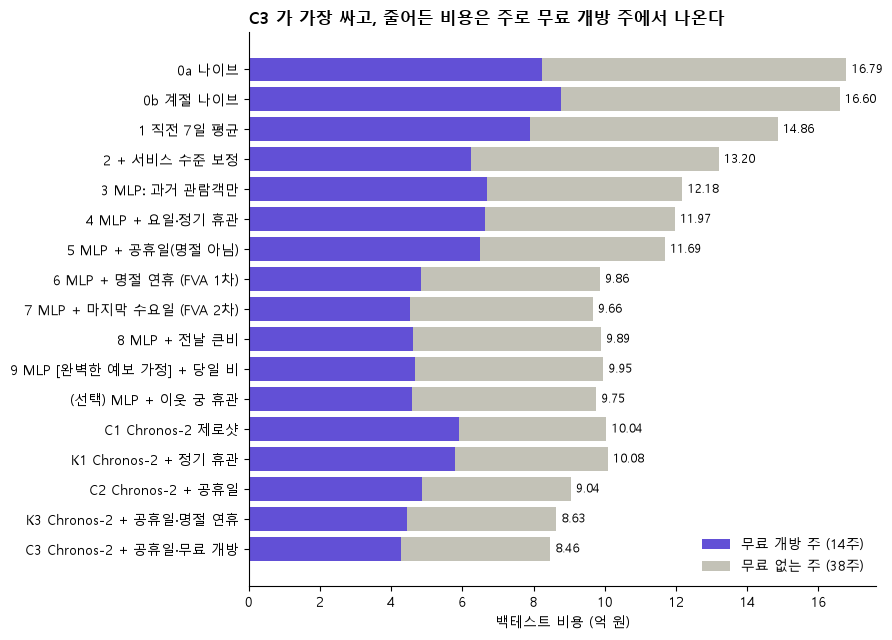

In [6]:
o = table('무료', '비용', scale=1e8)
o = o.loc[[m for m in o.index if '보정 A' not in m and '보정 B' not in m]].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(o.index, o['무료 O'], color=VIOLET, label='무료 개방 주 (14주)')
ax.barh(o.index, o['무료 X'], left=o['무료 O'], color='#c3c2b7', label='무료 없는 주 (38주)')
for i, (a, b) in enumerate(zip(o['무료 O'], o['무료 X'])):
    ax.text(a + b + 0.15, i, f'{a + b:.2f}', va='center', fontsize=8.5)
ax.set_xlabel('백테스트 비용 (억 원)'); ax.legend(loc='lower right', frameon=False)
ax.set_title('C3 가 가장 싸고, 줄어든 비용은 주로 무료 개방 주에서 나온다', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 6. 원점별 학습 구간 · 지표 값 (가이드 요구사항 2)

원점 52개마다 학습 구간 날짜와 베이스라인 3개 + 최종 모형 C3 의 WAPE · 비용. 보고서 ④ 「원점별 학습 구간 · 지표 값」과 같은 표다.

In [7]:
NAMES = {'0a 나이브': '나이브', '0b 계절 나이브': '계절 나이브', '1 직전 7일 평균': '직전 7일 평균', 'C3 Chronos-2 + 공휴일·무료 개방': 'C3'}
B = pd.read_parquet(DATA / 'backtests.parquet', filters=[('방식', 'in', list(NAMES)), ('확정', '==', '전날')])
B = B[B['status'] == 'open'].assign(ae=lambda x: (x['y'] - x['yhat']).abs(), 방식=lambda x: x['방식'].map(NAMES))
g = B.groupby(['origin', '방식'])
W = (g['ae'].sum() / g['y'].sum()).unstack()[list(NAMES.values())].add_prefix('WAPE ')
C = (g['cost'].sum() / 1e6).unstack()[['직전 7일 평균', 'C3']].add_prefix('비용(백만) ')
o = W.index.to_series()
P = pd.DataFrame({'주범주': B.drop_duplicates('origin').set_index('origin')['주범주'].str[0],
                  'MLP 학습': '2023-01-01 ~ ' + (o - pd.Timedelta(days=57)).dt.strftime('%Y-%m-%d'),
                  'MLP 검증': (o - pd.Timedelta(days=56)).dt.strftime('%m-%d') + ' ~ ' + (o - pd.Timedelta(days=1)).dt.strftime('%m-%d'),
                  'Chronos-2 입력': '2023-01-01 ~ ' + (o - pd.Timedelta(days=1)).dt.strftime('%Y-%m-%d'),
                  '예측(평가)': o.dt.strftime('%m-%d') + ' ~ ' + (o + pd.Timedelta(days=6)).dt.strftime('%m-%d')}).join(W).join(C)
P['WAPE 1위'] = W.idxmin(axis=1).str.replace('WAPE ', '')
P.index = P.index.strftime('%Y-%m-%d')
print('WAPE 1위 횟수:', P['WAPE 1위'].value_counts().to_dict(),
      '| C3 < 직전 7일 평균 (WAPE · 비용):', int((P['WAPE C3'] < P['WAPE 직전 7일 평균']).sum()), '·',
      int((P['비용(백만) C3'] < P['비용(백만) 직전 7일 평균']).sum()), '/ 52')
P.round(3)

WAPE 1위 횟수: {'C3': 39, '직전 7일 평균': 6, '계절 나이브': 4, '나이브': 3} | C3 < 직전 7일 평균 (WAPE · 비용): 44 · 48 / 52


,주범주,MLP 학습,MLP 검증,Chronos-2 입력,예측(평가),WAPE 나이브,WAPE 계절 나이브,WAPE 직전 7일 평균,WAPE C3,비용(백만) 직전 7일 평균,비용(백만) C3,WAPE 1위
origin,,,,,,,,,,,,
2025-01-01,C,2023-01-01 ~ 2024-11-05,11-06 ~ 12-31,2023-01-01 ~ 2024-12-31,01-01 ~ 01-07,0.520,0.494,0.552,0.313,10.661,8.005,C3
2025-01-08,D,2023-01-01 ~ 2024-11-12,11-13 ~ 01-07,2023-01-01 ~ 2025-01-07,01-08 ~ 01-14,0.318,0.581,0.510,0.359,5.485,6.955,나이브
2025-01-15,E,2023-01-01 ~ 2024-11-19,11-20 ~ 01-14,2023-01-01 ~ 2025-01-14,01-15 ~ 01-21,0.291,0.267,0.303,0.187,14.378,4.071,C3
2025-01-22,A,2023-01-01 ~ 2024-11-26,11-27 ~ 01-21,2023-01-01 ~ 2025-01-21,01-22 ~ 01-28,0.615,0.577,0.602,0.367,71.279,23.968,C3
2025-01-29,A,2023-01-01 ~ 2024-12-03,12-04 ~ 01-28,2023-01-01 ~ 2025-01-28,01-29 ~ 02-04,0.672,1.005,0.596,0.252,47.313,14.669,C3
2025-02-05,D,2023-01-01 ~ 2024-12-10,12-11 ~ 02-04,2023-01-01 ~ 2025-02-04,02-05 ~ 02-11,0.286,1.955,2.126,0.368,22.080,8.203,나이브
2025-02-12,E,2023-01-01 ~ 2024-12-17,12-18 ~ 02-11,2023-01-01 ~ 2025-02-11,02-12 ~ 02-18,0.284,0.360,0.344,0.208,20.460,5.626,C3
2025-02-19,E,2023-01-01 ~ 2024-12-24,12-25 ~ 02-18,2023-01-01 ~ 2025-02-18,02-19 ~ 02-25,0.247,0.245,0.317,0.192,6.638,6.451,C3
2025-02-26,B,2023-01-01 ~ 2024-12-31,01-01 ~ 02-25,2023-01-01 ~ 2025-02-25,02-26 ~ 03-04,0.345,0.423,0.355,0.261,27.032,10.809,C3
